# Quantum simulation of the 1D Schrödinger equation in a harmonic well

Mi-Song Dupuy  
2026-10-20

The goal of this TP is to simulate a *partial differential equation* on
a quantum register. We consider the Schrödinger equation with a harmonic
potential

<span id="eq-schrodinger">$$
\left\lbrace
\begin{aligned}
\mathrm{i}\partial_t \psi(x,t) &= \Big(-\Delta + V(x)\Big)\psi(x,t), \quad x \in [0,1),\ t \geq 0,\\
\psi(x,0) &= \psi_0(x),
\end{aligned}\right.
 \qquad(1)$$</span>

with periodic boundary conditions and
$V(x) = \left(x - \frac{1}{2}\right)^2$ the harmonic well
$\frac{1}{2}x^2$ centered in the middle of the periodic cell. In the
following, we will select $\psi_0(x) = \sqrt{ 2 } \sin(2 \pi (x-1/2))$.

# Discretisation scheme

## Finite-difference approximation

A finite-difference discretisation of the problem will be used in order
to approximate the solution to this problem. The grid is $x_j = j/N$,
$0 \leq j \leq N-1$ where $N=2^n$ is the number of discretisation
points. In the finite-difference method, the solution $\psi(t)$ is
approximated on the grid points $(x_j)_{0 \leq j \leq N-1}$, hence the
approximate solution is a vector $\psi^N(t)$ such that
$\psi^N_j(t) \simeq \psi(x_j,t)$ for any $0 \leq j \leq N-1$ and any
$t \in \mathbb{R}$.

In that setting, the multiplication operator by the function $V$ is
approximated by a diagonal matrix $V_N$ with entries

$$
V_N = \begin{bmatrix}
V(x_0) & & & \\ 
& V(x_1) & & \\ 
& & \ddots & \\ 
& & & V(x_{N-1})
\end{bmatrix}.
$$

The Laplacian is approximated using the discrete Fourier transform $F_N$
by

$$
-\Delta_N = 4 \pi^2 \, F_N^* \mathrm{diag}(0,1^2,\dots, (N/2)^2, (N/2-1)^2, (N/2-2)^2, \dots, 1) F_N. 
$$

The discrete time evolution problem is thus

<span id="eq-discrete-schrodinger">$$
\left\lbrace
\begin{aligned}
\mathrm{i}\partial_t \psi^N(t) &= \Big(-\Delta_N + V_N\Big)\psi^N(t), \quad t \geq 0,\\
\psi_j^N(0) &= \psi_0(x_j), \quad \forall \, 0 \leq j \leq N-1.
\end{aligned}\right.
 \qquad(2)$$</span>

The discrete solution $\psi^N$ to this evolution is given by
$\psi^N(t) = e^{-\mathrm{i}(-\Delta_N + V_N)t} \psi^N(0)$.

## Trotter splitting

We aim to solve
<a href="#eq-discrete-schrodinger" class="quarto-xref">Equation 2</a> on
the quantum computer. The time-discretisation scheme must preserve the
Euclidean norm of the approximate solution.

Unfortunately, it is not straightforward to implement the evolution
$e^{-\mathrm{i}(-\Delta_N + V_N)t}$ using a simple quantum circuit.
However, it turns out that both $e^{-\mathrm{i}(-\Delta_N)t}$ and
$e^{-\mathrm{i}V_Nt}$ have simple expressions in terms of elementary
quantum gates. Since $-\Delta_N$ and $V_N$ do not commute, we do not
have
$e^{-\mathrm{i}(-\Delta_N + V_N)t} = e^{-\mathrm{i}(-\Delta_N)t}e^{-\mathrm{i}V_Nt}$,
but we have it approximatively

$$
e^{-\mathrm{i}(-\Delta_N + V_N)t} = \Big( e^{-\mathrm{i}(-\Delta_N)t/J}e^{-\mathrm{i}V_Nt/J} \Big)^J + \mathcal{O}\Big( \frac{1}{J} \Big).
$$

In the quantum implementation, we will implement exactly the evolution

<span id="eq-discrete-schrodinger-trotter">$$
| \psi^{N,J} \rangle = \Big( e^{-\mathrm{i}(-\Delta_N)t/J}e^{-\mathrm{i}V_Nt/J} \Big)^J  \psi^N(0).
 \qquad(3)$$</span>

**Questions**

1.  Write a function that returns the solution of the discrete evolution
    problem
    <a href="#eq-discrete-schrodinger" class="quarto-xref">Equation 2</a>
    for any $t$. Recall that
    $\psi_0(x) = \sqrt{ 2 } \sin(2 \pi (x-1/2))$.
2.  Write a function that returns its approximate solution via the
    Trotter scheme.

In [1]:
import numpy as np


def psi0(N):
    x = np.arange(N) / N
    return np.sqrt(2) * np.sin(2 * np.pi * (x - 0.5))


def potential(N):
    x = np.arange(N) / N
    return (x - 0.5) ** 2


def laplacian_eigenvalues(N):
    # Eigenvalues of -Delta_N in the DFT basis.
    # The ordering matches np.fft.fftfreq, i.e. the diagonal
    # diag(0,1^2,...,(N/2)^2,(N/2-1)^2,...,1) since the values are squared.
    k = np.concatenate((
        np.arange(0, N // 2 + 1),
        np.arange(N // 2 - 1, 0, -1),
    ))
    return 4 * np.pi**2 * k**2


def hamiltonian(N):
    U = np.fft.fft(np.eye(N)) / np.sqrt(N)
    return (U.conj().T * laplacian_eigenvalues(N)) @ U + np.diag(potential(N))


def solution(t, N=128):
    # Solution of the discrete evolution problem: exp(-i(-Delta_N + V_N)t) psi^N(0).
    H = hamiltonian(N)
    w, Q = np.linalg.eigh(H)
    return Q @ (np.exp(-1j * w * t) * (Q.conj().T @ psi0(N)))


def solution_trotter(t, N=128, J=100):
    # Trotter approximation: (exp(-i(-Delta_N)t/J) exp(-i V_N t/J))^J psi^N(0).
    psi = psi0(N).astype(complex)
    d = np.exp(-1j * laplacian_eigenvalues(N) * t / J)
    v = np.exp(-1j * potential(N) * t / J)
    for _ in range(J):
        psi = np.fft.ifft(np.fft.fft(psi) * d)
        psi = v * psi
    return psi

# Quantum implementation of the Trotter scheme

We now focus on the quantum implementation of the Trotter scheme. On the
quantum computer, the approximate solution $\psi^N$ is encoded as a wave
function

$$
| \psi^N  \rangle = \sum_{ j=0 }^{2^n-1 } \psi_j^N | j \rangle.
$$

To implement the Trotter scheme, we need two quantum circuits

- one to initialise to $\frac{1}{\sqrt{ N }} \psi^N(0)$ the quantum
  computation
- another one to perform a single Trotter step
  $e^{-\mathrm{i}(-\Delta_N)t/J}e^{-\mathrm{i}V_Nt/J}$.

For the term, $e^{-\mathrm{i}V_Nt/J}$, we will see how to expand the
diagonal matrix $V_N$ into sums of Pauli $Z$ matrices to get a quantum
circuit for this evolution.

For the term $e^{-\mathrm{i}(-\Delta_N)t/J}$, we have that

$$
e^{-\mathrm{i}(-\Delta_N)t/J} = F_N^* \exp\{- \mathrm{i} 4 \pi^2 t/J \mathrm{diag}(0,1^2,\dots, (N/2)^2, (N/2-1)^2, (N/2-2)^2, \dots, 1)\} F_N.
$$

The matrices $F_N$ are given by the QFT, and the diagonal matrix
appearing is very similar to the one given by the quadratic potential
$V_N$ (up to some shift of indices). In the following, after deriving
the quantum circuit of $e^{-\mathrm{i}V_Nt/J}$, the analogous quantum
circuit for
$\exp\{- \mathrm{i} 4 \pi^2 t/J \mathrm{diag}(0,1^2,\dots, (N/2)^2, (N/2-1)^2, (N/2-2)^2, \dots, 1)\}$
will be given.

## Potential term

We first write $V$ as a sum of Pauli $Z$ matrices. In the following, for
$0 \leq k \leq n-1$, we will use the short-hand notation

$$
Z_k = I^{\otimes k} \otimes Z \otimes I^{\otimes (n-k-1)} \in \mathbb{C}^{2^n \times 2^n}.
$$

The multiplication operator by $x$ on the grid $(x_j)$ is discretised in
the finite-difference method by the diagonal matrix

$$
V_N = \begin{bmatrix}
(x_0-1/2)^2 & & & \\ 
& (x_1-1/2)^2 & & \\ 
& & \ddots & \\ 
& & & (x_{N-1}-1/2)^2
\end{bmatrix}.
$$

This means that for any canonical vector $e_j, 0 \leq j \leq 2^n-1$, we
have $V_N e_j = \Big(\sum_{k=0}^{n-1} 2^{-k-1} j_k- \frac{1}{2} \Big)^2$
where $(j_{n-1},\dots,j_{0})$ is the binary encoding of the integer $j$,
*i.e* $j=\sum_{k=0}^{n-1} 2^{n-1-k} j_k$.

**Questions**

1.  show that the diagonal matrix $\begin{bmatrix}
      0 & 0 \\ 0 & 1
    \end{bmatrix} = \frac{I-Z}{2}$.
2.  for $0 \leq k \leq n-1$, let $J_k$ be the diagonal matrix such that
    $J_k e_j = j_k e_j$, for $0 \leq j \leq 2^n-1$. Show that
    $J_k = \frac{I-Z_k}{2}$.
3.  let $X_N \in \mathbb{C}^{2^n \times 2^n}$ be the diagonal matrix
    with entries $(x_j)_{0 \leq j \leq 2^n-1}$. Show that

$$
X_N - \frac{I}{2} = \sum_{ k=0 }^{n-1 } 2^{-k-1} \frac{I-Z_k}{2} - \frac{I}{2} = - \frac{1}{2^{n+1}} I - \sum_{ k=0 }^{n-1 } 2^{-k-2} Z_k. 
$$

1.  check that

$$
V_N = \Big(X_N - \frac{1}{2}I \Big)^2 = \Big( \frac{1}{12} + \frac{1}{6 \cdot 4^n} \Big) I + \frac{1}{4\cdot 2^n} \sum_{ k=0 }^{n-1 } 2^{-k} Z_k + \frac{1}{8} \sum_{ 0 \leq k<\ell \leq n-1 } 2^{-k-\ell } Z_k Z_{\ell}.
$$

We now want to implement the quantum circuit corresponding to
$e^{\mathrm{i} \theta V_N}$ for $\theta \in \mathbb{R}$.

**Questions**

1.  check that the matrices $Z_j$ and $Z_{k}Z_{\ell}$ commute
2.  deduce that

$$
e^{\mathrm{i}\theta V_N} = e^{\mathrm{i}\theta \big( \frac{1}{12} + \frac{1}{6 \cdot 4^n} \big) } \prod_{k=0}^{n-1} e^{\mathrm{i} \frac{\theta}{4 \cdot 2^{n+k}} Z_k} \prod_{0 \leq k<\ell \leq n-1} e^{\mathrm{i} \frac{\theta}{2^{k+\ell+3}} Z_k Z_{\ell}}.
$$

It remains to check how to implement efficiently
$e^{\mathrm{i}\phi Z_k Z_{\ell}}$ rotations.

1.  show that

$$
\mathrm{CNOT} \big( I \otimes Z  \big) \mathrm{CNOT} = Z \otimes Z.
$$

1.  deduce that

$$
e^{\mathrm{i} \phi Z \otimes  Z} = \mathrm{CNOT} \big(  I \otimes e^{\mathrm{i} \phi Z}  \big)\mathrm{CNOT}.
$$

1.  deduce that there is asymptotically $O(n^2)$ elementary gates to
    implement $e^{\mathrm{i}\theta V_N}$.

The circuit for $e^{\mathrm{i}\theta V_N}$ is implemented in MyQLM as
follows. MyQLM orders qubits so that qubit $q$ carries the bit of weight
$2^q$ (little-endian), so the Pauli $Z_k$ acts on qubit $n-1-k$, and the
rotation gate satisfies
$\mathrm{RZ}(\varphi) = e^{-\mathrm{i}\varphi Z/2}$, so that
$e^{\mathrm{i}\varphi Z} = \mathrm{RZ}(-2\varphi)$ exactly. The circuit
equals $e^{\mathrm{i}\theta V_N}$ up to the single global phase
$e^{-\mathrm{i}\theta \big( \frac{1}{12} + \frac{1}{6 \cdot 4^n} \big)}$
coming from the identity term of $V_N$.

In [2]:
from qat.lang.AQASM import QRoutine, RZ, CNOT


def exp_i_theta_VN(n, theta):
    """Circuit implementing exp(i*theta*V_N) on n qubits, up to the global
    phase exp(-i*theta*(1/12 + 1/(6*4^n))), where
    V_N = diag((j/2^n - 1/2)^2)_{0 <= j < 2^n}.

    Gate count: n single-qubit rotations + n(n-1)/2 CNOT-RZ-CNOT blocks,
    i.e. O(n^2) elementary gates.
    """
    qrout = QRoutine()
    q = qrout.new_wires(n)

    # Single-qubit rotations exp(i * theta/(4*2^{n+k}) * Z_k),
    # with Z_k acting on qubit n-1-k (little-endian convention).
    for k in range(n):
        qrout.apply(RZ(-2 * theta / (4 * 2 ** (n + k))), q[n - 1 - k])

    # Two-qubit rotations exp(i * theta/2^{k+l+3} * Z_k Z_l)
    # via CNOT * exp(i*phi*Z_l) * CNOT.
    for k in range(n):
        for l in range(k + 1, n):
            qk, ql = q[n - 1 - k], q[n - 1 - l]
            phi = theta / 2 ** (k + l + 3)
            qrout.apply(CNOT, qk, ql)
            qrout.apply(RZ(-2 * phi), ql)
            qrout.apply(CNOT, qk, ql)

    return qrout

## Kinetic term

We now derive the quantum circuit of $e^{-\mathrm{i}\theta \Delta_N}$
for $\theta \in \mathbb{R}$, the case of interest in the Trotter scheme
being $\theta = -t/J$. Recall that $-\Delta_N = 4 \pi^2 F_N^* D F_N$
with

$$
D = \mathrm{diag}(0,1^2,\dots, (N/2)^2, (N/2-1)^2, \dots, 1),
$$

so that

$$
e^{-\mathrm{i}\theta \Delta_N} = F_N^* \, e^{\mathrm{i} 4 \pi^2 \theta D} \, F_N:
$$

the circuit is a QFT, followed by diagonal phase rotations, followed by
an inverse QFT.

The diagonal entries of $D$ are indexed by the frequencies of the
discrete Fourier transform: the frequency associated with the index $j$,
$0 \leq j \leq 2^n-1$, is $k_j = j$ if $j \leq N/2$ and $k_j = j - N$ if
$j > N/2$, *i.e.* the two’s complement $k_j = j - N j_0 = N(x_j - j_0)$
of $j$.

**Questions**

1.  check that $D = S^2$ where $S = \mathrm{diag}(k_0, \dots, k_{N-1})$.
2.  using the expansion of $X_N - \frac{I}{2}$ obtained for the
    potential term, show that

$$
S = N (X_N - J_0) = - \frac{I}{2} + 2^{n-2} Z_0 - \sum_{k=1}^{n-1} 2^{n-2-k} Z_k. 
$$

1.  deduce that

$$
D = a I + \sum_{k=0}^{n-1} b_k Z_k + \sum_{0 \leq k < \ell \leq n-1} b_{k \ell} Z_k Z_{\ell}
$$

with

$$
a = \frac{4^n + 2}{12}, \qquad 
b_0 = - 2^{n-2}, \quad b_k = 2^{n-2-k} \ (k \geq 1), \qquad 
b_{0 \ell} = - 2^{2n-3-\ell}, \quad b_{k \ell} = 2^{2n-3-k-\ell} \ (1 \leq k < \ell).
$$

All the terms of this decomposition commute, so for
$\varphi = 4 \pi^2 \theta$,

$$
e^{\mathrm{i}\varphi D} = e^{\mathrm{i}\varphi a} \prod_{k=0}^{n-1} e^{\mathrm{i}\varphi b_k Z_k} \prod_{0 \leq k < \ell \leq n-1} e^{\mathrm{i}\varphi b_{k \ell} Z_k Z_{\ell}},
$$

where the single- and two-qubit rotations are implemented like in the
potential term. The global phase $e^{\mathrm{i}\varphi a}$ is
unobservable, and there are $O(n^2)$ elementary gates, to which the two
QFTs have to be added.

Like for the potential term, MyQLM orders qubits so that qubit $q$
carries the bit of weight $2^q$, so $Z_k$ acts on qubit $n-1-k$, and the
rotations use $\mathrm{RZ}(\varphi) = e^{-\mathrm{i}\varphi Z/2}$, so
that $e^{\mathrm{i}\varphi Z} = \mathrm{RZ}(-2\varphi)$ exactly. The QFT
is built explicitly: the routine `qft` below implements
$|j\rangle \mapsto \frac{1}{\sqrt{2^n}} \sum_x e^{2 \mathrm{i} \pi jx/2^n} |x\rangle$
in the little-endian convention (the built-in
`qat.lang.AQASM.qftarith.QFT` outputs the amplitudes in reversed bit
order, which would not be consistent with the indexing of $D$). Since a
controlled $\mathrm{PH}(\theta)$ is exactly the textbook controlled
phase $\mathrm{diag}(1,1,1,e^{\mathrm{i}\theta})$, the QFT is the
standard textbook circuit. The circuit equals
$e^{-\mathrm{i}\theta \Delta_N}$ up to the single global phase
$e^{-\mathrm{i} 4\pi^2 \theta \frac{4^n + 2}{12}}$ coming from the
identity term of $D$.

In [3]:
import numpy as np

from qat.lang.AQASM import QRoutine, PH, CNOT, H, RZ, SWAP


def qft(n):
    """Little-endian QFT: |j> -> (1/sqrt(2^n)) sum_x exp(2i*pi*j*x/2^n)|x>.

    Since PH(theta) = diag(1, e^{i*theta}), the controlled gate
    PH(theta).ctrl() is exactly the textbook controlled phase
    diag(1, 1, 1, e^{i*theta}).
    """
    qrout = QRoutine()
    q = qrout.new_wires(n)
    for t in range(n - 1, -1, -1):
        qrout.apply(H, q[t])
        for c in range(t):
            qrout.apply(PH(np.pi / 2 ** (t - c)).ctrl(), q[c], q[t])
    for i in range(n // 2):
        qrout.apply(SWAP, q[i], q[n - 1 - i])
    return qrout


def exp_i_theta_DeltaN(n, theta):
    """Circuit implementing exp(-i*theta*Delta_N) on n qubits, up to the
    global phase exp(-i*4*pi^2*theta*(4^n+2)/12), where
    -Delta_N = 4*pi^2 F_N^dag D F_N.

    Gate count: two QFTs plus O(n^2) phase rotations. The Trotter kinetic
    factor exp(-i*(-Delta_N)*t/J) corresponds to theta = -t/J.
    """
    phi = 4 * np.pi**2 * theta
    qrout = QRoutine()
    q = qrout.new_wires(n)

    qrout.apply(qft(n), q)

    # exp(i*phi*D) with D = a I + sum_k b_k Z_k + sum_{k<l} b_{kl} Z_k Z_l,
    # with Z_k acting on qubit n-1-k (little-endian convention).
    # The global phase exp(-i*phi*a) comes from the identity term of D.
    for k in range(n):
        b = -2 ** (n - 2) if k == 0 else 2 ** (n - 2 - k)
        qrout.apply(RZ(-2 * phi * b), q[n - 1 - k])
    for k in range(n):
        for l in range(k + 1, n):
            b = -2 ** (2 * n - 3 - l) if k == 0 else 2 ** (2 * n - 3 - k - l)
            qk, ql = q[n - 1 - k], q[n - 1 - l]
            qrout.apply(CNOT, qk, ql)
            qrout.apply(RZ(-2 * phi * b), ql)
            qrout.apply(CNOT, qk, ql)

    qrout.apply(qft(n).dag(), q)
    return qrout

## Trotter steps

To run the full scheme, the register is first initialised in the state
$\frac{1}{\sqrt{N}}\psi^N(0)$. Since

$$
\psi_0(x) = \sqrt{2}\sin\Big(2\pi\big(x - \tfrac{1}{2}\big)\Big) = \frac{\mathrm{i}}{\sqrt{2}}\Big( e^{2\mathrm{i}\pi x} - e^{-2\mathrm{i}\pi x} \Big),
$$

the vector $\psi^N(0)$ is supported on the two Fourier modes $k = \pm 1$
only, and

$$
\frac{1}{\sqrt{N}} \psi^N(0) = \mathrm{QFT} \Big[ \frac{\mathrm{i}}{\sqrt{2}} \big( |1\rangle - |N-1\rangle \big) \Big],
$$

where the indices $1$ and $N-1$ carry the frequencies $+1$ and $-1$.

**Questions**

1.  check the formula above.
2.  show that the state
    $\frac{1}{\sqrt{2}}\big(|1\rangle - |N-1\rangle\big)$ can be
    prepared with $O(n)$ elementary gates.
3.  deduce the full quantum circuit for $| \psi^{N,J} \rangle$ and its
    gate count as a function of $n$ and $J$.

The simulation below initialises the register, applies $J$ Trotter steps
(the kinetic circuit, then the potential circuit, as in
`solution_trotter`), and extracts the probabilities $|\psi|^2$ from the
exact amplitudes of the simulator. They are compared with the classical
solution `solution` and the classical Trotter approximation
`solution_trotter` of the first part.

quantum vs classical Trotter:  1.940114735532461e-14
classical Trotter vs exact:    3.767645781037332e-05

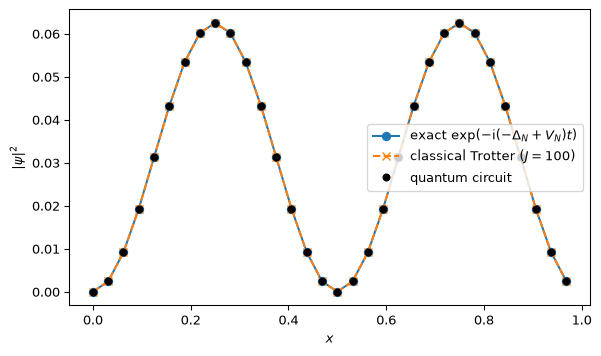

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from qat.lang.AQASM import QRoutine, Program, PH, CNOT, X, H
from qat.qpus import PyLinalg


def prepare_psi0(n):
    """Circuit preparing (1/sqrt(N)) psi^N(0), up to a global phase:
    (|1> - |N-1>)/sqrt(2) followed by a QFT."""
    qrout = QRoutine()
    q = qrout.new_wires(n)
    # bit 0 is 1 in both |1> and |N-1>; bits 1..n-1 are all 0 in |1> and
    # all 1 in |N-1>: a GHZ state with a relative phase -1.
    qrout.apply(X, q[0])
    qrout.apply(H, q[1])
    for i in range(2, n):
        qrout.apply(CNOT, q[1], q[i])
    qrout.apply(PH(np.pi), q[1])
    # map the Fourier modes k = +-1 to the position basis
    qrout.apply(qft(n), q)
    return qrout


def simulate(n, t, J):
    """Full Trotter evolution on n qubits: initialisation, then J steps
    (kinetic circuit exp(-i(-Delta_N)t/J), then potential circuit
    exp(-i V_N t/J)), and measurement of the probabilities |psi|^2."""
    prog = Program()
    qreg = prog.qalloc(n)
    prog.apply(prepare_psi0(n), qreg)
    for _ in range(J):
        prog.apply(exp_i_theta_DeltaN(n, -t / J), qreg)
        prog.apply(exp_i_theta_VN(n, -t / J), qreg)
    result = PyLinalg().submit(prog.to_circ().to_job())
    proba = np.zeros(2**n)
    for sample in result:
        proba[sample.state.lsb_int] = sample.probability
    return proba


n, t, J = 5, 1.0, 100
N = 2**n

proba_q = simulate(n, t, J)
p_exact = np.abs(solution(t, N=N)) ** 2
p_exact /= p_exact.sum()
p_trotter = np.abs(solution_trotter(t, N=N, J=J)) ** 2
p_trotter /= p_trotter.sum()

print("quantum vs classical Trotter: ", np.max(np.abs(proba_q - p_trotter)))
print("classical Trotter vs exact:   ", np.max(np.abs(p_trotter - p_exact)))

x = np.arange(N) / N
plt.figure(figsize=(7, 4))
plt.plot(x, p_exact, "o-", label=r"exact $\exp(-\mathrm{i}(-\Delta_N+V_N)t)$")
plt.plot(x, p_trotter, "x--", label=f"classical Trotter ($J={J}$)")
plt.plot(x, proba_q, "k.", ms=10, label="quantum circuit")
plt.xlabel("$x$")
plt.ylabel(r"$|\psi|^2$")
plt.legend()
plt.show()